# Fabric Notebook - Lago di Bracciano: lakehouse, risultati annuali, semantic model e forecast 2027

Questo notebook è pensato per Microsoft Fabric e fa queste cose:

1. usa i dati iniziali del problema del lago di Bracciano;
2. applica le **funzioni a tratti** ricavate dal testo per generare i risultati nel tempo;
3. salva le tabelle nel **lakehouse** collegato al notebook;
4. crea un **semantic model Direct Lake** pronto per Power BI;
5. esegue un **forecast AutoML per il 2027** a partire dalla serie storica generata dal modello matematico.

> **Nota importante**
>
> Le osservazioni reali disponibili sono annuali (2016-2026). Per dare ad AutoML una serie temporale più ricca, il notebook genera una serie **mensile sintetica** derivata dalle funzioni del problema. Quindi il forecast 2027 è basato sul **modello matematico**, non su nuove misure osservate.


## Modello matematico usato

Poniamo `x = anni trascorsi dal 1° gennaio 2016`, quindi:

- `x = 0` corrisponde al 01/01/2016
- `x = 1` corrisponde al 01/01/2017
- ...
- `x = 10` corrisponde al 01/01/2026

Dai dati del testo si ricavano i parametri:

- `a = -1/2`
- `b = -1`
- `c = 7/2`
- `m = 2`
- `k = -12`

Quindi la funzione a tratti è:

\[
 f(x) =
 \begin{cases}
 -\frac{1}{2}(x-2)^4 - (x-2)^3 + \frac{7}{2}(x-2)^2 - 20 & \text{per } 0 \le x \le 3 \\
 2x - 24 + \sin^2(\pi x) & \text{per } 3 < x \le 7 \\
 2\cos^2(2\pi x) - 12 & \text{per } 7 < x \le 10
 \end{cases}
\]

Le misure iniziali (in decimetri rispetto allo zero idrometrico) sono:

| Anno | Valore |
|---|---:|
| 2016 | -6 |
| 2017 | -16 |
| 2018 | -20 |
| 2019 | -18 |
| 2020 | -16 |
| 2021 | -14 |
| 2022 | -12 |
| 2023 | -10 |
| 2024 | -10 |
| 2025 | -10 |
| 2026 | -10 |


## Prerequisiti Fabric

Prima di eseguire il notebook:

1. crea un **workspace Fabric**;
2. crea **un nuovo Notebook**;
3. **aggiungi o crea un Lakehouse** e collegalo al notebook (il notebook salva tutto nel lakehouse collegato);
4. se vuoi creare il semantic model Direct Lake, assicurati che il workspace sia su capacità Fabric e che il tuo profilo possa creare item nel workspace.

Se vuoi automatizzare anche la parte di semantic model via notebook, questo notebook usa **Semantic Link Labs**.


In [22]:
# Parametri modificabili
WORKSPACE_NAME = None   # None = workspace corrente del notebook
SEMANTIC_MODEL_NAME = "sm_bracciano_livello_lago"

INPUT_TABLE = "bracciano_input"
YEARLY_TABLE = "bracciano_modeled_yearly"
MONTHLY_TABLE = "bracciano_modeled_monthly"
REPORT_TABLE = "bracciano_report_ready"
FORECAST_MONTHLY_TABLE = "bracciano_forecast_2027_monthly"
FORECAST_YEARLY_TABLE = "bracciano_forecast_2027_yearly"

# Il modello matematico del testo è definito da x=0 (01/01/2016) a x=10 (01/01/2026)
MODEL_END_DATE = "2026-01-01"

# Per ottenere il forecast del solo anno 2027 a partire dall'ultimo punto noto (2026-01)
# faccio predire 24 mesi e poi filtro i 12 mesi del 2027.
AUTOML_FULL_FORECAST_HORIZON_MONTHS = 24
AUTOML_TIME_BUDGET_SECONDS = 60
DISPLAY_DECIMALS = 3


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 32, Finished, Available, Finished, False)

In [23]:
# Librerie
import math
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:.{DISPLAY_DECIMALS}f}")

try:
    from flaml import AutoML
except Exception:
    # In Fabric spesso FLAML è già presente; se non lo fosse, abilita questa riga:
    # %pip install "flaml[automl,ts_forecast]"
    raise


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 33, Finished, Available, Finished, False)

In [24]:
# Dati iniziali del problema
observed_data = pd.DataFrame({
    "year": [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    "x":    [0,    1,    2,    3,    4,    5,    6,    7,    8,    9,    10],
    "level_dm": [-6, -16, -20, -18, -16, -14, -12, -10, -10, -10, -10]
})
observed_data["date"] = pd.to_datetime(observed_data["year"].astype(str) + "-01-01")
observed_data


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 34, Finished, Available, Finished, False)

,year,x,level_dm,date
0,2016,0,-6,2016-01-01
1,2017,1,-16,2017-01-01
2,2018,2,-20,2018-01-01
3,2019,3,-18,2019-01-01
4,2020,4,-16,2020-01-01
5,2021,5,-14,2021-01-01
6,2022,6,-12,2022-01-01
7,2023,7,-10,2023-01-01
8,2024,8,-10,2024-01-01
9,2025,9,-10,2025-01-01


In [25]:
# Funzioni a tratti ricavate dal testo

def f_piecewise(x: float) -> float:
    if 0 <= x <= 3:
        return -0.5 * (x - 2)**4 - (x - 2)**3 + 3.5 * (x - 2)**2 - 20
    elif 3 < x <= 7:
        return 2 * x - 24 + (math.sin(math.pi * x) ** 2)
    elif 7 < x <= 10:
        return 2 * (math.cos(2 * math.pi * x) ** 2) - 12
    elif x == 7:
        return -10.0
    else:
        raise ValueError(f"x fuori dominio gestito: {x}")


def get_segment(x: float) -> str:
    if 0 <= x <= 3:
        return "polinomiale_2016_2019"
    elif 3 < x <= 7:
        return "crescita_oscillante_2019_2023"
    elif 7 < x <= 10:
        return "oscillante_2023_2026"
    elif x == 7:
        return "crescita_oscillante_2019_2023"
    return "out_of_scope"


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 35, Finished, Available, Finished, False)

In [26]:
# Tabella annuale calcolata con il modello (2016-2026)
yearly = pd.DataFrame({
    "x": np.arange(0, 11, 1, dtype=float)
})
yearly["year"] = 2016 + yearly["x"].astype(int)
yearly["date"] = pd.to_datetime(yearly["year"].astype(str) + "-01-01")
yearly["modeled_level_dm"] = yearly["x"].apply(f_piecewise)
yearly["segment"] = yearly["x"].apply(get_segment)

yearly_check = yearly.merge(observed_data[["year", "level_dm"]], on="year", how="left")
yearly_check["delta_vs_observed"] = yearly_check["modeled_level_dm"] - yearly_check["level_dm"]
yearly_check


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 36, Finished, Available, Finished, False)

,x,year,date,modeled_level_dm,segment,level_dm,delta_vs_observed
0,0.000,2016,2016-01-01,-6.000,polinomiale_2016_2019,-6,0.000
1,1.000,2017,2017-01-01,-16.000,polinomiale_2016_2019,-16,0.000
2,2.000,2018,2018-01-01,-20.000,polinomiale_2016_2019,-20,0.000
3,3.000,2019,2019-01-01,-18.000,polinomiale_2016_2019,-18,0.000
4,4.000,2020,2020-01-01,-16.000,crescita_oscillante_2019_2023,-16,0.000
5,5.000,2021,2021-01-01,-14.000,crescita_oscillante_2019_2023,-14,0.000
6,6.000,2022,2022-01-01,-12.000,crescita_oscillante_2019_2023,-12,0.000
7,7.000,2023,2023-01-01,-10.000,crescita_oscillante_2019_2023,-10,0.000
8,8.000,2024,2024-01-01,-10.000,oscillante_2023_2026,-10,0.000
9,9.000,2025,2025-01-01,-10.000,oscillante_2023_2026,-10,0.000


In [27]:
# Serie mensile sintetica solo nel dominio del modello: 2016-01 .. 2026-01
monthly_dates = pd.date_range("2016-01-01", MODEL_END_DATE, freq="MS")
monthly = pd.DataFrame({"date": monthly_dates})
monthly["x"] = ((monthly["date"].dt.year - 2016) + (monthly["date"].dt.month - 1) / 12.0).astype(float)
monthly["modeled_level_dm"] = monthly["x"].apply(f_piecewise)
monthly["segment"] = monthly["x"].apply(get_segment)
monthly["year"] = monthly["date"].dt.year
monthly["month"] = monthly["date"].dt.month
monthly.tail(24)


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 37, Finished, Available, Finished, False)

,date,x,modeled_level_dm,segment,year,month
97,2024-02-01,8.083,-10.500,oscillante_2023_2026,2024,2
98,2024-03-01,8.167,-11.500,oscillante_2023_2026,2024,3
99,2024-04-01,8.250,-12.000,oscillante_2023_2026,2024,4
100,2024-05-01,8.333,-11.500,oscillante_2023_2026,2024,5
101,2024-06-01,8.417,-10.500,oscillante_2023_2026,2024,6
102,2024-07-01,8.500,-10.000,oscillante_2023_2026,2024,7
103,2024-08-01,8.583,-10.500,oscillante_2023_2026,2024,8
104,2024-09-01,8.667,-11.500,oscillante_2023_2026,2024,9
105,2024-10-01,8.750,-12.000,oscillante_2023_2026,2024,10
106,2024-11-01,8.833,-11.500,oscillante_2023_2026,2024,11


In [28]:
# Preparo una tabella report-ready unica, utile per Power BI
observed_report = observed_data.copy()
observed_report = observed_report.rename(columns={"level_dm": "value_dm"})
observed_report["series_name"] = "Osservato_annuale"
observed_report["grain"] = "year"
observed_report["source_type"] = "observed"
observed_report["segment"] = observed_report["x"].apply(get_segment)

modeled_yearly_report = yearly.copy()
modeled_yearly_report = modeled_yearly_report.rename(columns={"modeled_level_dm": "value_dm"})
modeled_yearly_report["series_name"] = "Modello_annuale"
modeled_yearly_report["grain"] = "year"
modeled_yearly_report["source_type"] = "modeled"

modeled_monthly_report = monthly.copy()
modeled_monthly_report = modeled_monthly_report.rename(columns={"modeled_level_dm": "value_dm"})
modeled_monthly_report["series_name"] = "Modello_mensile"
modeled_monthly_report["grain"] = "month"
modeled_monthly_report["source_type"] = "modeled"

report_ready = pd.concat([
    observed_report[["date", "year", "x", "value_dm", "segment", "series_name", "grain", "source_type"]],
    modeled_yearly_report[["date", "year", "x", "value_dm", "segment", "series_name", "grain", "source_type"]],
    modeled_monthly_report[["date", "year", "x", "value_dm", "segment", "series_name", "grain", "source_type"]],
], ignore_index=True).sort_values(["date", "series_name"]).reset_index(drop=True)

report_ready.head(20)


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 38, Finished, Available, Finished, False)

,date,year,x,value_dm,segment,series_name,grain,source_type
0,2016-01-01,2016,0.000,-6.000,polinomiale_2016_2019,Modello_annuale,year,modeled
1,2016-01-01,2016,0.000,-6.000,polinomiale_2016_2019,Modello_mensile,month,modeled
2,2016-01-01,2016,0.000,-6.000,polinomiale_2016_2019,Osservato_annuale,year,observed
3,2016-02-01,2016,0.083,-6.849,polinomiale_2016_2019,Modello_mensile,month,modeled
4,2016-03-01,2016,0.167,-7.723,polinomiale_2016_2019,Modello_mensile,month,modeled
5,2016-04-01,2016,0.250,-8.611,polinomiale_2016_2019,Modello_mensile,month,modeled
6,2016-05-01,2016,0.333,-9.506,polinomiale_2016_2019,Modello_mensile,month,modeled
7,2016-06-01,2016,0.417,-10.399,polinomiale_2016_2019,Modello_mensile,month,modeled
8,2016-07-01,2016,0.500,-11.281,polinomiale_2016_2019,Modello_mensile,month,modeled
9,2016-08-01,2016,0.583,-12.146,polinomiale_2016_2019,Modello_mensile,month,modeled


## Salvataggio nel Lakehouse

Le tabelle seguenti vengono salvate come Delta table nel lakehouse collegato:

- `bracciano_input`
- `bracciano_modeled_yearly`
- `bracciano_modeled_monthly`
- `bracciano_report_ready`

Se il notebook non è collegato a un lakehouse, le celle sotto daranno errore: in quel caso collega prima il lakehouse dal pannello a sinistra del notebook.


In [29]:
# Scrittura tabelle nel Lakehouse
spark.createDataFrame(observed_data).write.mode("overwrite").format("delta").saveAsTable(INPUT_TABLE)
spark.createDataFrame(yearly).write.mode("overwrite").format("delta").saveAsTable(YEARLY_TABLE)
spark.createDataFrame(monthly).write.mode("overwrite").format("delta").saveAsTable(MONTHLY_TABLE)
spark.createDataFrame(report_ready).write.mode("overwrite").format("delta").saveAsTable(REPORT_TABLE)

print("Tabelle scritte nel lakehouse:")
for t in [INPUT_TABLE, YEARLY_TABLE, MONTHLY_TABLE, REPORT_TABLE]:
    print(" -", t)


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 39, Finished, Available, Finished, False)

Tabelle scritte nel lakehouse:
 - bracciano_input
 - bracciano_modeled_yearly
 - bracciano_modeled_monthly
 - bracciano_report_ready


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 40, Finished, Available, Finished, False)

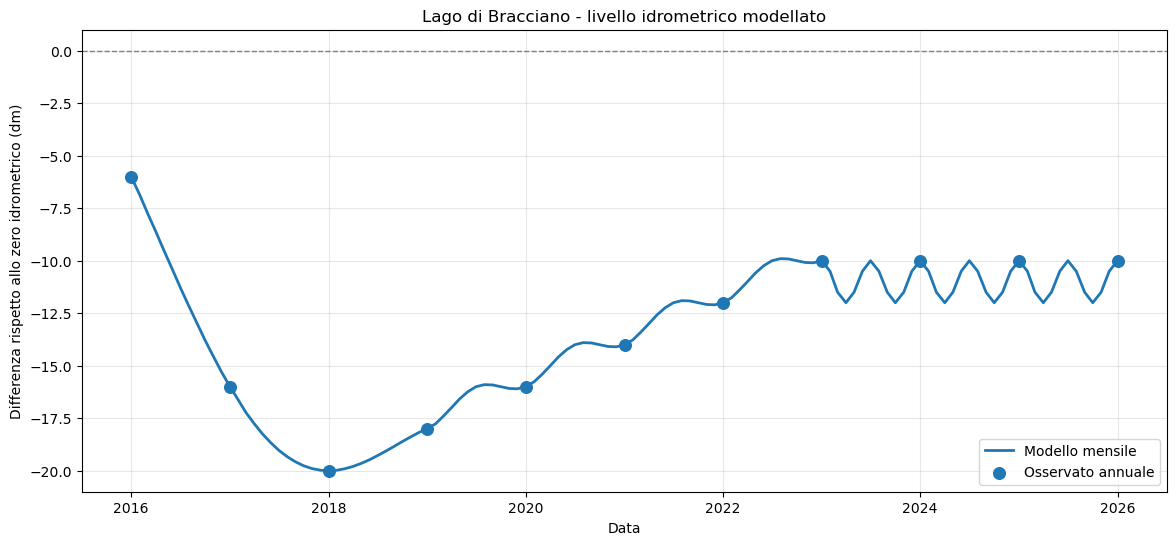

In [30]:
# Visualizzazione veloce nel notebook
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(monthly["date"], monthly["modeled_level_dm"], label="Modello mensile", linewidth=2)
plt.scatter(observed_data["date"], observed_data["level_dm"], label="Osservato annuale", s=70, zorder=3)
plt.title("Lago di Bracciano - livello idrometrico modellato")
plt.xlabel("Data")
plt.ylabel("Differenza rispetto allo zero idrometrico (dm)")
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Forecast AutoML per il 2027

AutoML in Fabric usa **FLAML** e supporta il task di **time series forecasting**.

Qui alleniamo il modello sulla serie mensile sintetica 2016-01 / 2026-12 e chiediamo un forecast di 12 mesi (gennaio-dicembre 2027).


In [31]:
# Dataset storico per AutoML
train_ts = monthly[["date", "modeled_level_dm"]].copy().sort_values("date")
X_train = train_ts["date"].values.astype("datetime64[ns]")
y_train = train_ts["modeled_level_dm"].values

# Forecast continuo da 2026-02 fino a 2027-01 (12 mesi, nessun buco)
FORECAST_HORIZON_MONTHS = 12
forecast_dates = pd.date_range("2026-02-01", periods=FORECAST_HORIZON_MONTHS, freq="MS")
X_forecast = forecast_dates.values.astype("datetime64[ns]")

automl = AutoML()
automl_settings = {
    "task": "ts_forecast",
    "metric": "mape",
    "eval_method": "holdout",
    "period": FORECAST_HORIZON_MONTHS,
    "time_budget": AUTOML_TIME_BUDGET_SECONDS,
    "log_file_name": "bracciano_automl_forecast.log",
    # "estimator_list": ["arima", "sarimax", "prophet", "lgbm", "rf", "xgboost"]
}

automl.fit(X_train=X_train, y_train=y_train, **automl_settings)
forecast_values = automl.predict(X_forecast)

# Niente più filtro per anno: tengo tutto il forecast
forecast_monthly = pd.DataFrame({
    "date": forecast_dates,
    "year": forecast_dates.year,
    "month": forecast_dates.month,
    "forecast_level_dm": np.array(forecast_values, dtype=float),
    "best_estimator": automl.best_estimator,
})
forecast_monthly["series_name"] = "Forecast_AutoML"
forecast_monthly["grain"] = "month"
forecast_monthly["source_type"] = "forecast"

forecast_monthly
forecast_2027_monthly = forecast_monthly  # alias per le celle successive

StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 41, Finished, Available, Finished, False)

INFO:trident_token_library_wrapper:Calling getAccessToken from PyTridentTokenLibrary
INFO:trident_token_library_wrapper:Calling getAccessToken from PyTridentTokenLibrary
INFO:trident_token_library_wrapper:Calling getAccessToken from PyTridentTokenLibrary
INFO:trident_token_library_wrapper:Calling getAccessToken from PyTridentTokenLibrary
INFO:trident_token_library_wrapper:Calling getAccessToken from PyTridentTokenLibrary


[flaml.automl.logger: 06-22 09:04:38] {2716} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'arima', 'sarimax', 'prophet']
[flaml.automl.logger: 06-22 09:04:38] {3029} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 06-22 09:04:38] {3164} INFO - Estimated sufficient time budget=2006s. Estimated necessary time budget=2s.


[flaml.automl.logger: 06-22 09:04:41] {3215} INFO -  at 3.5s,	estimator lgbm's best error=1.6091e-01,	best estimator lgbm's best error=1.6091e-01
[flaml.automl.logger: 06-22 09:04:41] {3029} INFO - iteration 1, current learner lgbm


[flaml.automl.logger: 06-22 09:04:43] {3215} INFO -  at 6.6s,	estimator lgbm's best error=1.6091e-01,	best estimator lgbm's best error=1.6091e-01
[flaml.automl.logger: 06-22 09:04:43] {3029} INFO - iteration 2, current learner lgbm


[flaml.automl.logger: 06-22 09:04:45] {3215} INFO -  at 8.8s,	estimator lgbm's best error=8.0432e-02,	best estimator lgbm's best error=8.0432e-02
[flaml.automl.logger: 06-22 09:04:45] {3029} INFO - iteration 3, current learner lgbm


... (6 outputs left out)

[flaml.automl.logger: 06-22 09:05:20] {3215} INFO -  at 44.7s,	estimator lgbm's best error=4.4065e-02,	best estimator lgbm's best error=4.4065e-02
[flaml.automl.logger: 06-22 09:05:20] {3029} INFO - iteration 10, current learner lgbm


[flaml.automl.logger: 06-22 09:05:34] {3215} INFO -  at 46.6s,	estimator lgbm's best error=4.4065e-02,	best estimator lgbm's best error=4.4065e-02
[flaml.automl.logger: 06-22 09:05:34] {3029} INFO - iteration 11, current learner lgbm


[flaml.automl.logger: 06-22 09:05:36] {3215} INFO -  at 60.0s,	estimator lgbm's best error=3.0524e-02,	best estimator lgbm's best error=3.0524e-02
[flaml.automl.logger: 06-22 09:05:36] {3477} INFO - retrain lgbm for 0.2s
[flaml.automl.logger: 06-22 09:05:36] {3480} INFO - retrained model: <flaml.automl.time_series.sklearn.SklearnWrapper object at 0x7684d7f5f4d0>
[flaml.automl.logger: 06-22 09:05:36] {3481} INFO - Auto Feature Engineering pipeline: None
[flaml.automl.logger: 06-22 09:05:36] {3483} INFO - Best MLflow run name: lemon_glass_ksn800l7
[flaml.automl.logger: 06-22 09:05:36] {3484} INFO - Best MLflow run id: 2fe8f179-8942-4fcf-ae29-4056c6a0369f
[flaml.automl.logger: 06-22 09:05:36] {3533} WARNING - Exception for log_model task record_state-pickle_and_log_automl_artifacts_lgbm: Run with UUID ec435435-d62d-4697-b624-097fb1781b29 is already active. To start a new run, first end the current run with mlflow.end_run(). To start a nested run, call start_run with nested=True


[flaml.automl.logger: 06-22 09:05:48] {2752} INFO - fit succeeded
[flaml.automl.logger: 06-22 09:05:48] {2753} INFO - Time taken to find the best model: 60.04554224014282


In [32]:
# Sintesi annuale 2027
forecast_2027_yearly = pd.DataFrame({
    "year": [2027],
    "date": [pd.Timestamp("2027-01-01")],
    "forecast_level_dm_mean": [forecast_2027_monthly["forecast_level_dm"].mean()],
    "forecast_level_dm_min": [forecast_2027_monthly["forecast_level_dm"].min()],
    "forecast_level_dm_max": [forecast_2027_monthly["forecast_level_dm"].max()],
    "best_estimator": [automl.best_estimator],
    "series_name": ["Forecast_AutoML_2027"],
    "grain": ["year"],
    "source_type": ["forecast"],
})

forecast_2027_yearly


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 42, Finished, Available, Finished, False)

,year,date,forecast_level_dm_mean,forecast_level_dm_min,forecast_level_dm_max,best_estimator,series_name,grain,source_type
0,2027,2027-01-01,-11.206,-11.927,-10.754,lgbm,Forecast_AutoML_2027,year,forecast


In [33]:
# Scrittura forecast nel Lakehouse
spark.createDataFrame(forecast_2027_monthly).write.mode("overwrite").format("delta").saveAsTable(FORECAST_MONTHLY_TABLE)
spark.createDataFrame(forecast_2027_yearly).write.mode("overwrite").format("delta").saveAsTable(FORECAST_YEARLY_TABLE)

# Aggiungo anche il forecast alla tabella report-ready
forecast_report = forecast_2027_monthly.copy()
forecast_report["x"] = ((forecast_report["year"] - 2016) + (forecast_report["month"] - 1) / 12.0).astype(float)
forecast_report["value_dm"] = forecast_report["forecast_level_dm"]
forecast_report["segment"] = "forecast_2027"
forecast_report = forecast_report[["date", "year", "x", "value_dm", "segment", "series_name", "grain", "source_type"]]

report_ready_with_forecast = pd.concat([report_ready, forecast_report], ignore_index=True)
report_ready_with_forecast = report_ready_with_forecast.sort_values(["date", "series_name"]).reset_index(drop=True)

spark.createDataFrame(report_ready_with_forecast).write.mode("overwrite").format("delta").saveAsTable(REPORT_TABLE)

print("Forecast salvato nel lakehouse.")
print("Best estimator scelto da AutoML:", automl.best_estimator)


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 43, Finished, Available, Finished, False)

Forecast salvato nel lakehouse.
Best estimator scelto da AutoML: lgbm


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 52, Finished, Available, Finished, False)

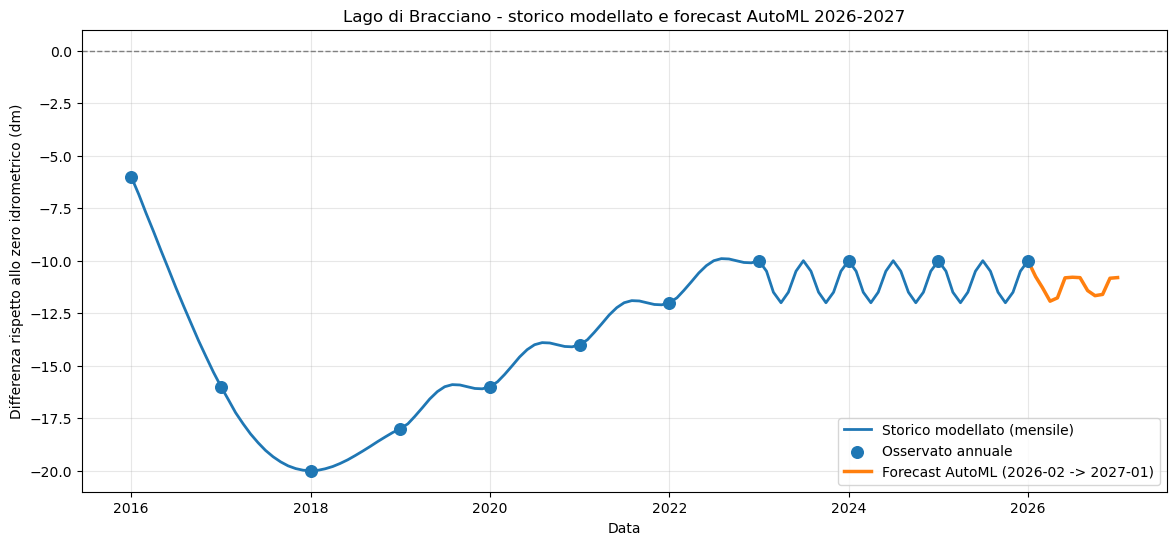

In [36]:
# Grafico finale: storico + forecast continuo (senza buco)
plt.figure(figsize=(14, 6))

plt.plot(monthly["date"], monthly["modeled_level_dm"],
         label="Storico modellato (mensile)", linewidth=2)
plt.scatter(observed_data["date"], observed_data["level_dm"],
            label="Osservato annuale", s=70, zorder=3)

# Aggancio: parto dall'ultimo punto storico (2026-01) e proseguo col forecast
last_hist = monthly[["date", "modeled_level_dm"]].tail(1).rename(
    columns={"modeled_level_dm": "forecast_level_dm"}
)
forecast_plot = pd.concat(
    [last_hist, forecast_monthly[["date", "forecast_level_dm"]]],
    ignore_index=True
)

plt.plot(forecast_plot["date"], forecast_plot["forecast_level_dm"],
         label="Forecast AutoML (2026-02 -> 2027-01)", linewidth=2.5)

plt.title("Lago di Bracciano - storico modellato e forecast AutoML 2026-2027")
plt.xlabel("Data")
plt.ylabel("Differenza rispetto allo zero idrometrico (dm)")
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Creazione del semantic model Direct Lake per Power BI

Questa cella prova a creare un **semantic model Direct Lake** basato sulle tabelle del lakehouse.

Tabelle incluse:

- `bracciano_report_ready`
- `bracciano_input`
- `bracciano_modeled_yearly`
- `bracciano_forecast_2027_yearly`

Se non hai la libreria installata, scommenta la riga `%pip install semantic-link-labs`.


In [37]:
# Creazione semantic model Direct Lake (opzionale ma consigliata)
# %pip install semantic-link-labs

import sempy_labs as labs

labs.directlake.generate_direct_lake_semantic_model(
    dataset=SEMANTIC_MODEL_NAME,
    lakehouse_tables=[REPORT_TABLE, INPUT_TABLE, YEARLY_TABLE, FORECAST_YEARLY_TABLE],
    workspace=WORKSPACE_NAME,
    lakehouse=None,
    lakehouse_workspace=None,
    overwrite=True,
    refresh=True
)

print(f"Semantic model creato/aggiornato: {SEMANTIC_MODEL_NAME}")


StatementMeta(, deab06e3-f5f9-41b3-915e-2a72f5fdc7ce, 54, Finished, Available, Finished, False)

TypeError: missing a required argument: 'tables'

## Report Power BI: cosa fare dopo

Il semantic model Direct Lake è pronto. Per creare il report Power BI nel modo più rapido:

1. apri il semantic model `sm_bracciano_livello_lago` nel workspace;
2. seleziona **New report** (oppure **Quick create**, se disponibile nel tuo ambiente);
3. crea almeno queste visualizzazioni:

### Visual 1 - andamento storico e forecast
- **Tipo**: line chart
- **Asse X**: `date`
- **Valori**: `value_dm`
- **Legenda**: `series_name`
- **Filtro consigliato**: `grain = month` per vedere la curva continua

### Visual 2 - confronto osservato vs modello annuale
- **Tipo**: clustered column chart
- **Asse X**: `year`
- **Valori**: `value_dm`
- **Legenda**: `series_name`
- **Filtro consigliato**: tieni solo `Osservato_annuale` e `Modello_annuale`

### Visual 3 - KPI forecast 2027
- **Tipo**: card
- **Valore**: `forecast_level_dm_mean` dalla tabella `bracciano_forecast_2027_yearly`

### Visual 4 - dettaglio segmenti del modello
- **Tipo**: line chart o matrix
- **Campi**: `date`, `value_dm`, `segment`

Se vuoi automatizzare anche la **creazione del report** via notebook, il modo più robusto è usare un template `report.json` e la funzione `create_report_from_reportjson()` di Semantic Link Labs.


## Tabelle finali nel Lakehouse

Alla fine del notebook hai queste tabelle:

- `bracciano_input` → dati iniziali osservati
- `bracciano_modeled_yearly` → risultati annuali del modello matematico
- `bracciano_modeled_monthly` → serie mensile sintetica derivata dal modello
- `bracciano_forecast_2027_monthly` → forecast AutoML mensile 2027
- `bracciano_forecast_2027_yearly` → sintesi annuale 2027
- `bracciano_report_ready` → tabella unica pronta per Power BI
